In [67]:
%pip install kagglehub


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [68]:
from pathlib import Path
import kagglehub

# Save the dataset inside project2/spotify_tracks_dataset
project2_dir = Path.cwd().resolve()
if project2_dir.name != "project2":
    project2_dir = project2_dir / "project2"

dataset_dir = project2_dir / "spotify_tracks_dataset"
dataset_dir.mkdir(parents=True, exist_ok=True)

path = kagglehub.dataset_download(
    "maharshipandya/-spotify-tracks-dataset",
    output_dir=str(dataset_dir),
)

print("Path to dataset files:", path)

Path to dataset files: /Users/yoon/Documents/Machine_Learning/project2/spotify_tracks_dataset


In [69]:
from pathlib import Path
import pandas as pd

csv_path = Path(path) / "dataset.csv"
df = pd.read_csv(csv_path)

print(f"File: {csv_path}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nColumns:")
for column in df.columns:
    print(f"- {column}")

print("\nMissing values per column:")
display(df.isna().sum().rename("missing_values").to_frame())

display(df.head())

File: /Users/yoon/Documents/Machine_Learning/project2/spotify_tracks_dataset/dataset.csv
Shape: 114,000 rows × 21 columns

Columns:
- Unnamed: 0
- track_id
- artists
- album_name
- track_name
- popularity
- duration_ms
- explicit
- danceability
- energy
- key
- loudness
- mode
- speechiness
- acousticness
- instrumentalness
- liveness
- valence
- tempo
- time_signature
- track_genre

Missing values per column:


,missing_values
Unnamed: 0,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [70]:
missing_artists = df[df["album_name"].isna()]
display(missing_artists.T)

,65900
Unnamed: 0,65900
track_id,1kR4gIb7nGxHPI3D2ifs59
artists,NaN
album_name,NaN
track_name,NaN
popularity,0
duration_ms,0
explicit,False
danceability,0.501
energy,0.583


In [71]:
missing_album_name = df[df["album_name"].isna()]
display(missing_album_name.T)

,65900
Unnamed: 0,65900
track_id,1kR4gIb7nGxHPI3D2ifs59
artists,NaN
album_name,NaN
track_name,NaN
popularity,0
duration_ms,0
explicit,False
danceability,0.501
energy,0.583


In [72]:
missing_track_name = df[df["track_name"].isna()]
display(missing_track_name.T)

,65900
Unnamed: 0,65900
track_id,1kR4gIb7nGxHPI3D2ifs59
artists,NaN
album_name,NaN
track_name,NaN
popularity,0
duration_ms,0
explicit,False
danceability,0.501
energy,0.583


In [73]:
print((df["duration_ms"] == 0).sum())

1


In [74]:
print(len(df))

zero_count = (df["duration_ms"] == 0).sum()
df = df[df["duration_ms"] != 0].copy()

print(f"{zero_count}개 행 삭제")
print(f"남은 행: {len(df):,}개")

114000
1개 행 삭제
남은 행: 113,999개


In [75]:
df.columns.tolist()

['Unnamed: 0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [76]:
print("데이터 크기:", df.shape)
print("\n전체 컬럼명:")
print(df.columns.tolist())

print("\n컬럼별 정보:")
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "결측 개수": df.isna().sum(),
    "결측 비율(%)": (df.isna().mean() * 100).round(2),
    "고유값 수": df.nunique()
}))

데이터 크기: (113999, 21)

전체 컬럼명:
['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

컬럼별 정보:


,dtype,결측 개수,결측 비율(%),고유값 수
Unnamed: 0,int64,0,0.0,113999
track_id,object,0,0.0,89740
artists,object,0,0.0,31437
album_name,object,0,0.0,46589
track_name,object,0,0.0,73608
popularity,int64,0,0.0,101
duration_ms,int64,0,0.0,50696
explicit,bool,0,0.0,2
danceability,float64,0,0.0,1174
energy,float64,0,0.0,2083


In [77]:
(df["explicit"].value_counts(normalize=True) * 100).round(2)

False    91.45
True      8.55
Name: explicit, dtype: float64

In [78]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [79]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,113999.0,33.238827,22.304959,0.000,17.0000,35.000000,50.0000,100.000
duration_ms,113999.0,228031.153387,107296.057716,8586.000,174066.0000,212906.000000,261506.0000,5237295.000
danceability,113999.0,0.566801,0.173543,0.000,0.4560,0.580000,0.6950,0.985
energy,113999.0,0.641383,0.251530,0.000,0.4720,0.685000,0.8540,1.000
key,113999.0,5.309126,3.559999,0.000,2.0000,5.000000,8.0000,11.000
loudness,113999.0,-8.258950,5.029357,-49.531,-10.0130,-7.004000,-5.0030,4.532
mode,113999.0,0.637558,0.480708,0.000,0.0000,1.000000,1.0000,1.000
speechiness,113999.0,0.084652,0.105733,0.000,0.0359,0.048900,0.0845,0.965
acousticness,113999.0,0.314907,0.332522,0.000,0.0169,0.169000,0.5975,0.996
instrumentalness,113999.0,0.156051,0.309556,0.000,0.0000,0.000042,0.0490,1.000


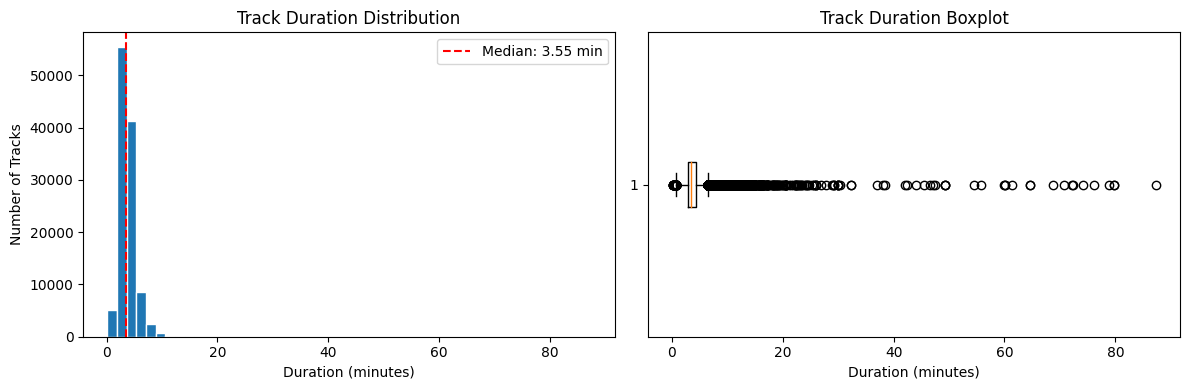

In [80]:
import matplotlib.pyplot as plt

duration_min = (
    df.loc[df["duration_ms"] > 0, "duration_ms"].dropna() / 60_000
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 분포 확인
axes[0].hist(duration_min, bins=50, edgecolor="white")
axes[0].axvline(duration_min.median(), color="red", linestyle="--",
                label=f"Median: {duration_min.median():.2f} min")
axes[0].set(title="Track Duration Distribution",
            xlabel="Duration (minutes)", ylabel="Number of Tracks")
axes[0].legend()

# 이상치 확인
axes[1].boxplot(duration_min, vert=False)
axes[1].set(title="Track Duration Boxplot", xlabel="Duration (minutes)")

plt.tight_layout()
plt.show()

In [81]:
df["duration_ms"]

0         230666
1         149610
2         210826
3         201933
4         198853
           ...  
113995    384999
113996    385000
113997    271466
113998    283893
113999    241826
Name: duration_ms, Length: 113999, dtype: int64

In [82]:
liveness = df["liveness"].dropna()
live_count = (liveness > 0.8).sum()
live_ratio = live_count / len(liveness) * 100

print(f"라이브 가능성이 높은 곡: {live_count}곡 ({live_ratio:.2f}%)")

라이브 가능성이 높은 곡: 3373곡 (2.96%)


In [83]:
print("중복 track_id 행:", df["track_id"].duplicated().sum())
print("고유 곡 수:", df["track_id"].nunique())

display(
    df.loc[df["track_id"].duplicated(keep=False),
           ["track_id", "track_name", "artists", "track_genre", "popularity"]]
      .sort_values("track_id")
      .head(10)
)

print("duration_ms가 0인 행:", (df["duration_ms"] == 0).sum())
print("tempo가 0인 행:", (df["tempo"] == 0).sum())
print("time_signature가 0인 행:", (df["time_signature"] == 0).sum())

중복 track_id 행: 24259
고유 곡 수: 89740


,track_id,track_name,artists,track_genre,popularity
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill,0
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul,0
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock,38
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska,38
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock,86
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative,86
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alt-rock,86
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,emo,58
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,sad,58
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,sertanejo,47


duration_ms가 0인 행: 0
tempo가 0인 행: 157
time_signature가 0인 행: 163


In [84]:
tempo_zero_rows = df.loc[df["tempo"] == 0]

print(f"tempo가 0인 행: {len(tempo_zero_rows)}개")

with pd.option_context("display.max_rows", None):
    display(tempo_zero_rows[
        ["track_name", "artists", "track_genre",
         "duration_ms", "tempo", "time_signature"]
    ])

tempo가 0인 행: 157개


,track_name,artists,track_genre,duration_ms,tempo,time_signature
4131,The Departure,Max Richter;Lang Lang,ambient,151506,0.0,0
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,ambient,73266,0.0,0
4664,Ferme Les Yeux,Sylvain Chauveau,ambient,68493,0.0,0
45670,Campomoro,Little Symphony,guitar,148711,0.0,0
45720,Ritornello,Little Symphony,guitar,102000,0.0,0
45729,Amager,Little Symphony,guitar,133624,0.0,0
45773,Ionian,Little Symphony,guitar,93125,0.0,0
59221,Yes! No! I Mean Yes! No I Don't!,Leila Bela,iranian,38333,0.0,0
59310,The Exorsism Begins...,Leila Bela,iranian,8586,0.0,0
59473,Leaving Her Quantum Journey Behind...,Leila Bela,iranian,50186,0.0,0


In [85]:
diff_rows = df.loc[
    (df["time_signature"] == 0) & (df["tempo"] != 0)
]

print(f"{len(diff_rows)}개 행")
display(diff_rows[[
    "track_name", "artists", "track_genre",
    "tempo", "time_signature"
]])

6개 행


,track_name,artists,track_genre,tempo,time_signature
2926,Sanki Yapamadım,Yaşlı Amca,alt-rock,138.616,0
26910,Here Comes the Sun (Piano Instrumental),Benny Martin,disney,93.948,0
76259,Você Existe Em Mim,Josh Groban,opera,153.274,0
79999,"""Farewell"" Jingle Bells",Dave Brubeck,piano,90.026,0
98298,Secondary Characters,Heidi Blickenstaff;Susan Blackwell,show-tunes,111.371,0
112172,Sanki Yapamadım,Yaşlı Amca,turkish,138.616,0


In [86]:
df_tracks = (
    df.sort_values("popularity", ascending=False)
      .drop_duplicates(subset="track_id", keep="first")
      .copy()
)

In [87]:
df_tracks = (
    df.sort_values("popularity", ascending=False)
      .drop_duplicates(subset="track_id", keep="first")
      .copy()
)

print("중복 track_id 행:", df_tracks["track_id"].duplicated().sum())
print("고유 곡 수:", df_tracks["track_id"].nunique())

display(
    df_tracks.loc[df_tracks["track_id"].duplicated(keep=False),
                  ["track_id", "track_name", "artists",
                   "track_genre", "popularity"]]
)

print("duration_ms가 0인 행:", (df_tracks["duration_ms"] == 0).sum())
print("tempo가 0인 행:", (df_tracks["tempo"] == 0).sum())
print("time_signature가 0인 행:",
      (df_tracks["time_signature"] == 0).sum())

중복 track_id 행: 0
고유 곡 수: 89740


,track_id,track_name,artists,track_genre,popularity


duration_ms가 0인 행: 0
tempo가 0인 행: 157
time_signature가 0인 행: 162


In [88]:
import numpy as np

df_tracks["time_signature"] = df_tracks["time_signature"].replace(0, np.nan)

print("time_signature 결측값 수:",
      df_tracks["time_signature"].isna().sum())

time_signature 결측값 수: 162


In [89]:
df_clean = df_tracks.copy()

cols = ["time_signature", "tempo"]
df_clean[cols] = df_clean[cols].replace(0, np.nan)
df_clean = df_clean.dropna(subset=cols).copy()

In [90]:
print("데이터 크기:", df_clean.shape)
print("\n전체 컬럼명:")
print(df_clean.columns.tolist())

print("\n컬럼별 정보:")
display(pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "결측 개수": df_clean.isna().sum(),
    "결측 비율(%)": (df_clean.isna().mean() * 100).round(2),
    "고유값 수": df_clean.nunique()
}))

데이터 크기: (89578, 20)

전체 컬럼명:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

컬럼별 정보:


,dtype,결측 개수,결측 비율(%),고유값 수
track_id,object,0,0.0,89578
artists,object,0,0.0,31387
album_name,object,0,0.0,46529
track_name,object,0,0.0,73466
popularity,int64,0,0.0,101
duration_ms,int64,0,0.0,50624
explicit,bool,0,0.0,2
danceability,float64,0,0.0,1173
energy,float64,0,0.0,2041
key,int64,0,0.0,12


In [91]:
display(df_clean.isna().sum().sort_values(ascending=False))

print("duration_ms가 0인 행:", (df_clean["duration_ms"] == 0).sum())
print("track_id 중복 행:", df_clean["track_id"].duplicated().sum())

audio_cols = [
    "danceability", "energy", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence"
]
display(df_clean[audio_cols].agg(["min", "max"]).T)

track_id            0
artists             0
time_signature      0
tempo               0
valence             0
liveness            0
instrumentalness    0
acousticness        0
speechiness         0
mode                0
loudness            0
key                 0
energy              0
danceability        0
explicit            0
duration_ms         0
popularity          0
track_name          0
album_name          0
track_genre         0
dtype: int64

duration_ms가 0인 행: 0
track_id 중복 행: 0


,min,max
danceability,0.05130,0.985
energy,0.00002,1.000
speechiness,0.02210,0.965
acousticness,0.00000,0.996
instrumentalness,0.00000,1.000
liveness,0.00925,1.000
valence,0.00000,0.995


In [92]:
from sklearn.preprocessing import StandardScaler

# 유사도 계산에 사용할 연속형 오디오 특성
continuous_cols = [
    "duration_ms", "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo"
]

# key와 time_signature는 범주형으로 원-핫 인코딩
category_cols = ["key", "time_signature"]
category_data = df_clean[category_cols].astype(int)
X_category = pd.get_dummies(
    category_data, columns=category_cols, dtype=int
)

# 연속형 특성만 표준화하고, mode는 0/1 그대로 유지
scaler = StandardScaler()
X_continuous = pd.DataFrame(
    scaler.fit_transform(df_clean[continuous_cols]),
    index=df_clean.index,
    columns=continuous_cols
)

X = pd.concat(
    [X_continuous, df_clean[["mode"]].astype(int), X_category],
    axis=1
)

# 추천 결과에 곡 정보를 다시 붙일 때 사용할 메타데이터
track_info = df_clean[
    ["track_id", "track_name", "artists", "album_name", "popularity"]
].copy()

print("모델 입력 데이터 크기:", X.shape)
print("모델 입력 컬럼:")
print(X.columns.tolist())
display(X.head().T)

모델 입력 데이터 크기: (89578, 27)
모델 입력 컬럼:
['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'mode', 'key_0', 'key_1', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8', 'key_9', 'key_10', 'key_11', 'time_signature_1', 'time_signature_3', 'time_signature_4', 'time_signature_5']


,20001,51664,89411,81210,68304
duration_ms,-0.646945,-0.271195,-0.595997,-0.483247,0.129474
danceability,0.860621,0.330007,1.550990,-0.012325,0.495467
energy,-0.638892,0.573418,0.170618,1.289072,0.311403
loudness,0.212376,0.565208,0.607501,0.927309,0.632800
speechiness,-0.010563,-0.384725,-0.451792,-0.470323,1.459609
acousticness,-0.931588,-0.933067,0.754294,-0.958710,-0.676340
instrumentalness,-0.534087,-0.431966,-0.534095,-0.534079,-0.533201
liveness,0.254388,0.069150,0.007404,0.794666,-0.465983
valence,-0.885460,0.303764,1.447249,-0.633893,-1.079852
tempo,0.297864,0.193916,0.091146,0.194152,-0.525138


In [93]:
# K-Means와 GMM은 같은 표본에서 비교합니다.
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from threadpoolctl import threadpool_limits

X_cluster_sample = X.sample(n=min(6000, len(X)), random_state=42)
X_cluster_array = X_cluster_sample.to_numpy(dtype=np.float32)
cluster_results = []

def evaluate_partition(method, k, labels, data, **extra):
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)
    sizes = pd.Series(labels).value_counts()
    row = {
        "method": method, "k": k,
        "silhouette": np.nan, "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
        "min_cluster_size": int(sizes.min()),
        "max_cluster_size": int(sizes.max()),
    }
    if 2 <= len(unique_labels) < len(labels):
        row["silhouette"] = silhouette_score(
            data, labels, sample_size=min(1500, len(data)), random_state=42
        )
        row["davies_bouldin"] = davies_bouldin_score(data, labels)
        row["calinski_harabasz"] = calinski_harabasz_score(data, labels)
    row.update(extra)
    return row

with threadpool_limits(limits=4):
    for k in [2, 3, 4, 5, 6, 8, 10]:
        km = KMeans(n_clusters=k, n_init=5, random_state=42)
        labels = km.fit_predict(X_cluster_array)
        cluster_results.append(evaluate_partition(
            "K-Means", k, labels, X_cluster_array, inertia=km.inertia_
        ))

    for k in [2, 3, 4, 5, 6, 8, 10]:
        gmm = GaussianMixture(
            n_components=k, covariance_type="diag", n_init=1,
            max_iter=100, reg_covar=1e-5, random_state=42
        )
        labels = gmm.fit_predict(X_cluster_array)
        cluster_results.append(evaluate_partition(
            "GMM", k, labels, X_cluster_array,
            bic=gmm.bic(X_cluster_array), aic=gmm.aic(X_cluster_array)
        ))

cluster_comparison = pd.DataFrame(cluster_results)
display(cluster_comparison.round(3))

,method,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size,inertia,bic,aic
0,K-Means,2,0.226,1.757,1298.974,1375,4625,55453.391,NaN,NaN
1,K-Means,3,0.133,2.209,1010.124,1180,2751,50463.047,NaN,NaN
2,K-Means,4,0.139,1.990,898.111,481,2526,46546.832,NaN,NaN
3,K-Means,5,0.135,1.920,838.064,452,2132,43268.254,NaN,NaN
4,K-Means,6,0.146,1.735,796.574,75,2123,40531.008,NaN,NaN
5,K-Means,8,0.121,1.752,726.304,71,1478,36496.285,NaN,NaN
6,K-Means,10,0.111,1.800,643.172,65,1122,34308.336,NaN,NaN
7,GMM,2,0.184,3.621,243.624,849,5151,NaN,-48529.365,-49259.612
8,GMM,3,0.003,7.386,102.838,362,2951,NaN,-250146.040,-251244.761
9,GMM,4,0.005,5.236,137.790,130,2436,NaN,-257553.581,-259020.774


In [94]:
# DBSCAN과 Mean Shift는 계산량이 커서 더 작은 동일 표본으로 점검합니다.
from sklearn.cluster import DBSCAN, MeanShift, estimate_bandwidth
from sklearn.neighbors import NearestNeighbors

density_results = []
X_density = X.sample(n=min(3000, len(X)), random_state=42).to_numpy(dtype=np.float32)

for min_samples in [10, 20]:
    neighbor_model = NearestNeighbors(n_neighbors=min_samples + 1, n_jobs=4)
    neighbor_model.fit(X_density)
    distances, _ = neighbor_model.kneighbors(X_density)
    k_distances = distances[:, -1]
    eps_values = np.quantile(k_distances, [0.90, 0.95, 0.98, 0.99])

    for eps in np.unique(np.round(eps_values, 3)):
        labels = DBSCAN(
            eps=float(eps), min_samples=min_samples, n_jobs=4
        ).fit_predict(X_density)
        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        sizes = pd.Series(labels[non_noise]).value_counts()
        row = {
            "method": "DBSCAN", "eps": eps,
            "min_samples": min_samples, "clusters": n_clusters,
            "noise_rate": 1 - non_noise.mean(),
            "min_cluster_size": int(sizes.min()) if len(sizes) else 0,
            "max_cluster_size": int(sizes.max()) if len(sizes) else 0,
            "silhouette": np.nan,
        }
        if n_clusters >= 2 and non_noise.sum() > 50:
            row["silhouette"] = silhouette_score(
                X_density[non_noise], labels[non_noise],
                sample_size=min(800, non_noise.sum()), random_state=42
            )
        density_results.append(row)

# Mean Shift은 특히 무거워서 1,200곡 표본으로 실행합니다.
X_meanshift = X.sample(n=min(1200, len(X)), random_state=42).to_numpy(dtype=np.float32)
bandwidth = estimate_bandwidth(
    X_meanshift, quantile=0.20, n_samples=min(300, len(X_meanshift)),
    random_state=42, n_jobs=4
)

if bandwidth > 0:
    ms = MeanShift(
        bandwidth=bandwidth, bin_seeding=True, min_bin_freq=5,
        cluster_all=False, n_jobs=4, max_iter=100
    )
    ms_labels = ms.fit_predict(X_meanshift)
    non_noise = ms_labels != -1
    n_clusters = len(set(ms_labels[non_noise]))
    sizes = pd.Series(ms_labels[non_noise]).value_counts()
    row = {
        "method": "Mean Shift", "bandwidth": bandwidth,
        "clusters": n_clusters, "noise_rate": 1 - non_noise.mean(),
        "min_cluster_size": int(sizes.min()) if len(sizes) else 0,
        "max_cluster_size": int(sizes.max()) if len(sizes) else 0,
        "silhouette": np.nan,
    }
    if n_clusters >= 2 and non_noise.sum() > 50:
        row["silhouette"] = silhouette_score(
            X_meanshift[non_noise], ms_labels[non_noise],
            sample_size=min(800, non_noise.sum()), random_state=42
        )
    density_results.append(row)

display(pd.DataFrame(density_results).round(3))

,method,eps,min_samples,clusters,noise_rate,min_cluster_size,max_cluster_size,silhouette,bandwidth
0,DBSCAN,2.634,10.0,1,0.040,2879,2879,NaN,NaN
1,DBSCAN,2.919,10.0,2,0.020,11,2928,0.523,NaN
2,DBSCAN,3.517,10.0,1,0.003,2991,2991,NaN,NaN
3,DBSCAN,3.850,10.0,1,0.001,2996,2996,NaN,NaN
4,DBSCAN,2.849,20.0,1,0.033,2900,2900,NaN,NaN
5,DBSCAN,3.184,20.0,1,0.018,2945,2945,NaN,NaN
6,DBSCAN,3.928,20.0,2,0.002,23,2971,0.528,NaN
7,DBSCAN,4.294,20.0,1,0.001,2997,2997,NaN,NaN
8,Mean Shift,NaN,NaN,1,0.286,857,857,NaN,3.45


In [95]:
# KNN은 군집화가 아니라, 선택한 곡의 최근접 곡을 찾는 추천 기준선입니다.
from sklearn.neighbors import NearestNeighbors

X_values = X.to_numpy(dtype=np.float32)
knn_model = NearestNeighbors(
    metric="cosine", algorithm="brute", n_neighbors=min(200, len(X)), n_jobs=4
)
knn_model.fit(X_values)

def recommend_knn(track_id, n=10):
    positions = np.flatnonzero(track_info["track_id"].to_numpy() == track_id)
    if len(positions) == 0:
        raise ValueError("track_id를 track_info에서 찾을 수 없습니다.")

    position = positions[0]
    search_n = min(max(100, n * 20), len(X_values))
    distances, indices = knn_model.kneighbors(
        X_values[position:position + 1], n_neighbors=search_n
    )
    seed = track_info.iloc[position]
    seed_key = (str(seed["track_name"]).casefold(), str(seed["artists"]).casefold())
    seen = set()
    rows = []

    for distance, candidate_position in zip(distances[0], indices[0]):
        candidate = track_info.iloc[candidate_position]
        candidate_key = (
            str(candidate["track_name"]).casefold(),
            str(candidate["artists"]).casefold()
        )
        if candidate_position == position or candidate_key == seed_key or candidate_key in seen:
            continue
        seen.add(candidate_key)
        rows.append({
            "track_id": candidate["track_id"],
            "track_name": candidate["track_name"],
            "artists": candidate["artists"],
            "album_name": candidate["album_name"],
            "popularity": candidate["popularity"],
            "cosine_similarity": 1 - distance
        })
        if len(rows) == n:
            break

    return pd.DataFrame(rows)

# 예시: popularity가 가장 높은 곡과 비슷한 곡 5개 확인
example_position = track_info["popularity"].to_numpy().argmax()
example_track = track_info.iloc[example_position]
print("기준 곡:", example_track["track_name"], "—", example_track["artists"])
display(recommend_knn(example_track["track_id"], n=5))

기준 곡: Unholy (feat. Kim Petras) — Sam Smith;Kim Petras


,track_id,track_name,artists,album_name,popularity,cosine_similarity
0,3DmW6y7wTEYHJZlLo1r6XJ,Shower,Becky G,Shower,78,0.947663
1,100fdP6bcT8byvdEdAAcTJ,Super Gremlin Freestyle,BadKidMacei,Super Gremlin Freestyle,23,0.940423
2,6VTHp0HzlexVgCZcuV2bkT,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,Pj Panda's New Nursery Rhymes Collection,12,0.917389
3,2mIfukfnSxDiMbh9xOxeZN,Baby Shark (Trap Remix),Pj Panda,"The New Nursery Rhymes, Vol. 1",37,0.917389
4,3mfsGLEmKF6sWTqFQzZ4aF,I'd Do Anything to Make You Smile,Jack Harlow,Hip Hop Slow Jamz,0,0.914592


In [96]:
# K-Means k=2와 k=6의 평균 특성을 비교해 해석 가능한지 확인합니다.
profile_source = df_clean.loc[X_cluster_sample.index, continuous_cols].copy()
profile_source["duration_min"] = profile_source["duration_ms"] / 60000
profile_cols = [
    "duration_min", "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo"
]

with threadpool_limits(limits=4):
    for k in [2, 6]:
        profile_model = KMeans(n_clusters=k, n_init=5, random_state=42)
        profile_source["cluster"] = profile_model.fit_predict(X_cluster_array)
        print(f"k={k} 군집별 곡 수와 평균 오디오 특성")
        display(profile_source.groupby("cluster")[profile_cols].mean().round(2))
        display(profile_source["cluster"].value_counts().sort_index().rename("곡 수").to_frame())

k=2 군집별 곡 수와 평균 오디오 특성


,duration_min,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,,
0,3.67,0.45,0.30,-14.90,0.06,0.75,0.38,0.17,0.28,109.54
1,3.83,0.60,0.74,-6.47,0.10,0.19,0.12,0.23,0.52,127.08


,곡 수
0,1375
1,4625


k=6 군집별 곡 수와 평균 오디오 특성


,duration_min,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,,
0,3.74,0.53,0.76,-6.85,0.09,0.29,0.07,0.73,0.54,124.02
1,3.50,0.69,0.73,-6.40,0.09,0.19,0.05,0.16,0.68,122.11
2,4.40,0.48,0.81,-6.12,0.08,0.07,0.29,0.19,0.31,137.26
3,3.57,0.54,0.39,-10.40,0.06,0.66,0.08,0.16,0.39,114.06
4,3.48,0.57,0.72,-10.16,0.81,0.69,0.01,0.69,0.43,104.68
5,3.77,0.35,0.19,-20.85,0.06,0.84,0.79,0.15,0.17,104.91


,곡 수
0,451
1,2123
2,1618
3,1250
4,75
5,483


/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 44400 (\N{HANGUL SYLLABLE GUN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 51665 (\N{HANGUL SYLLABLE JIB}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 45432 (\N{HANGUL SYLLABLE NO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/

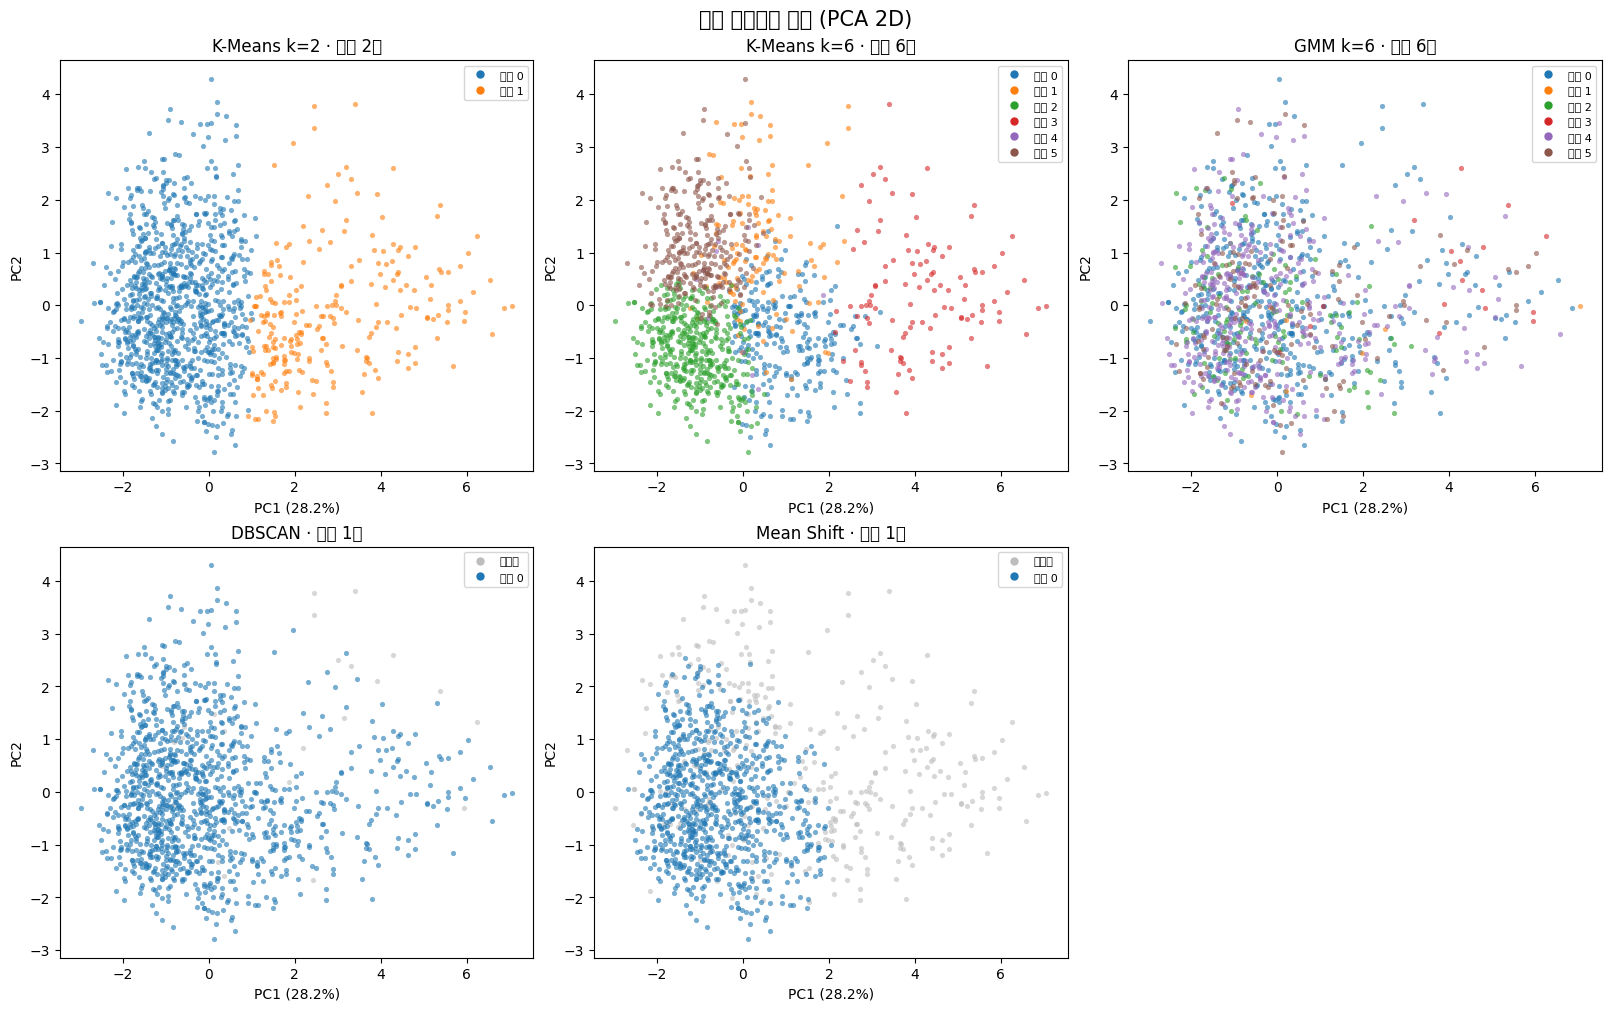

DBSCAN eps=3.126; 회색 점은 노이즈(-1)입니다. PCA는 시각화용 압축입니다.


In [98]:
# PCA로 27개 오디오 특성을 2차원에 표시해 군집 모양을 비교합니다.
# 실제 군집은 원래 특성 공간에서 계산하며, PCA는 눈으로 보는 용도입니다.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, MeanShift, estimate_bandwidth
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

X_viz = X.sample(n=min(1200, len(X)), random_state=42).to_numpy(dtype=np.float32)
pca_viz = PCA(n_components=2, random_state=42)
coords = pca_viz.fit_transform(X_viz)
visual_labels = {}

with threadpool_limits(limits=4):
    visual_labels['K-Means k=2'] = KMeans(n_clusters=2, n_init=5, random_state=42).fit_predict(X_viz)
    visual_labels['K-Means k=6'] = KMeans(n_clusters=6, n_init=5, random_state=42).fit_predict(X_viz)
    visual_labels['GMM k=6'] = GaussianMixture(n_components=6, covariance_type='diag', random_state=42).fit_predict(X_viz)

    min_samples = 10
    nn = NearestNeighbors(n_neighbors=min_samples + 1, n_jobs=4).fit(X_viz)
    distances, _ = nn.kneighbors(X_viz)
    eps = float(np.quantile(distances[:, -1], 0.95))
    visual_labels['DBSCAN'] = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=4).fit_predict(X_viz)

    bandwidth = estimate_bandwidth(X_viz, quantile=0.20, n_samples=min(300, len(X_viz)), random_state=42, n_jobs=4)
    if bandwidth > 0:
        visual_labels['Mean Shift'] = MeanShift(bandwidth=bandwidth, bin_seeding=True, min_bin_freq=5, cluster_all=False, n_jobs=4).fit_predict(X_viz)
    else:
        visual_labels['Mean Shift'] = np.zeros(len(X_viz), dtype=int)

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
colors = plt.get_cmap('tab10')
for ax, (method, labels) in zip(axes.ravel(), visual_labels.items()):
    handles = []
    for cid in sorted(np.unique(labels)):
        color = '#bdbdbd' if cid == -1 else colors(int(cid) % 10)
        mask = labels == cid
        ax.scatter(coords[mask, 0], coords[mask, 1], s=14, alpha=0.6, color=color, linewidths=0)
        name = '노이즈' if cid == -1 else f'군집 {cid}'
        handles.append(Line2D([], [], marker='o', linestyle='', color=color, label=name, markersize=5))
    count = len(set(labels) - {-1})
    ax.set_title(f'{method} · 군집 {count}개')
    ax.set_xlabel(f'PC1 ({pca_viz.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel('PC2')
    if len(handles) <= 8:
        ax.legend(handles=handles, fontsize=8)
axes[-1, -1].axis('off')
fig.suptitle('군집 알고리즘 비교 (PCA 2D)', fontsize=15)
plt.show()
print(f'DBSCAN eps={eps:.3f}; 회색 점은 노이즈(-1)입니다. PCA는 시각화용 압축입니다.')

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPyt

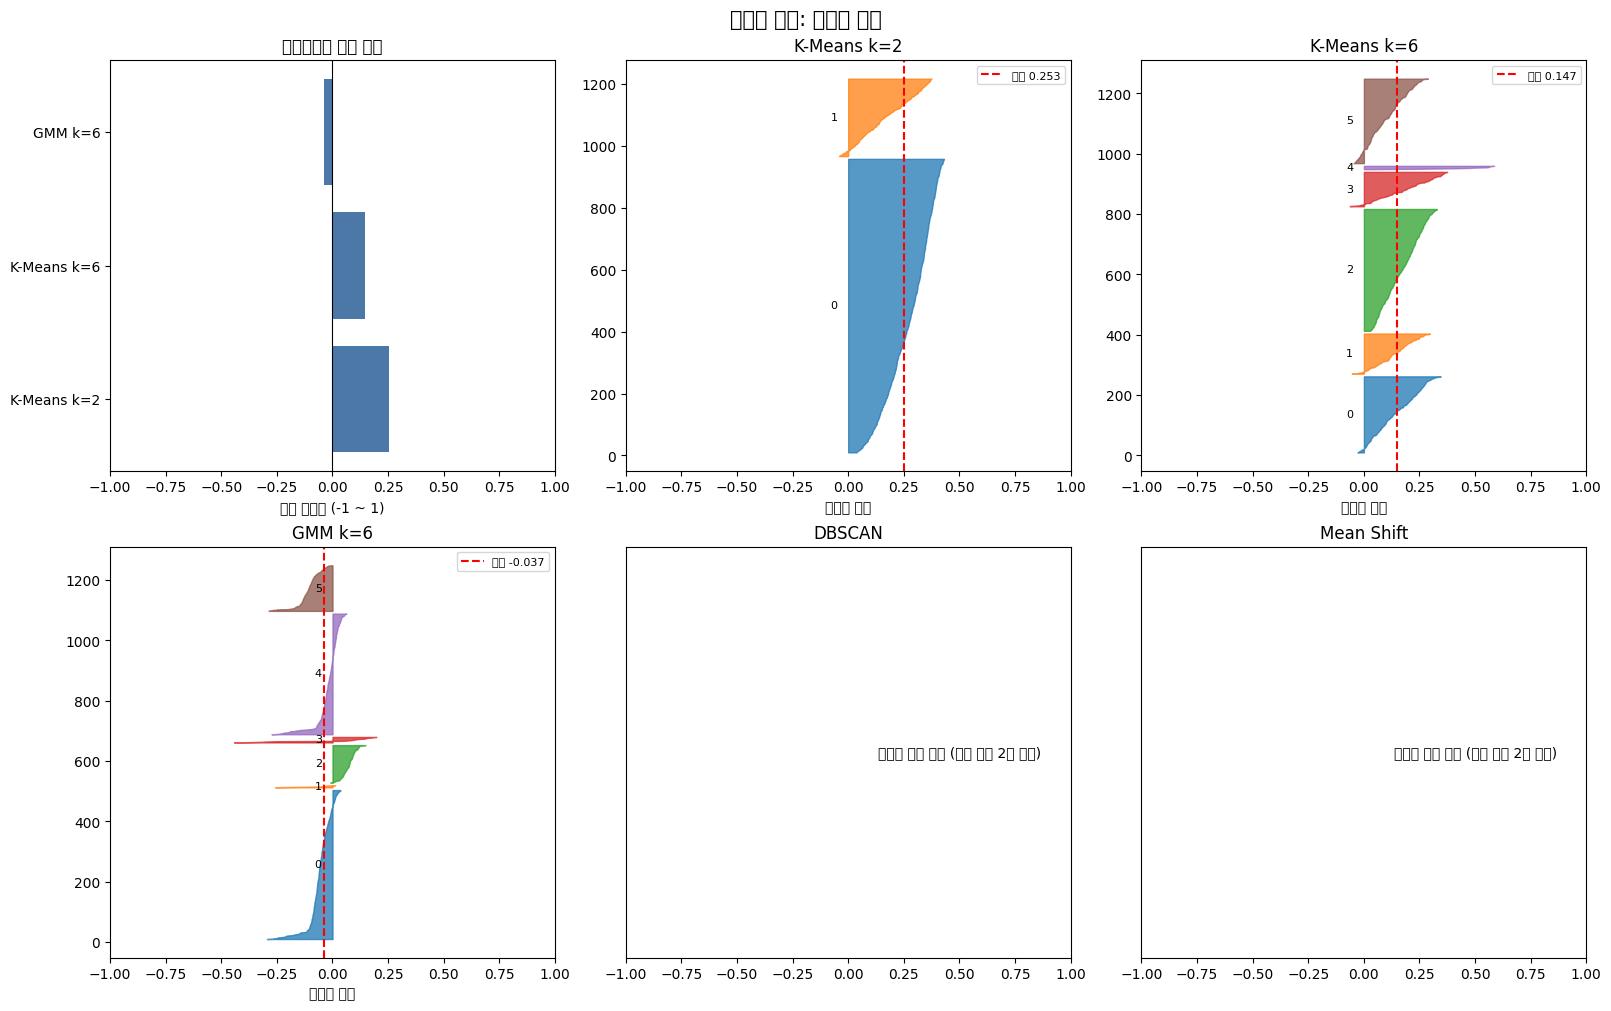

/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPyt

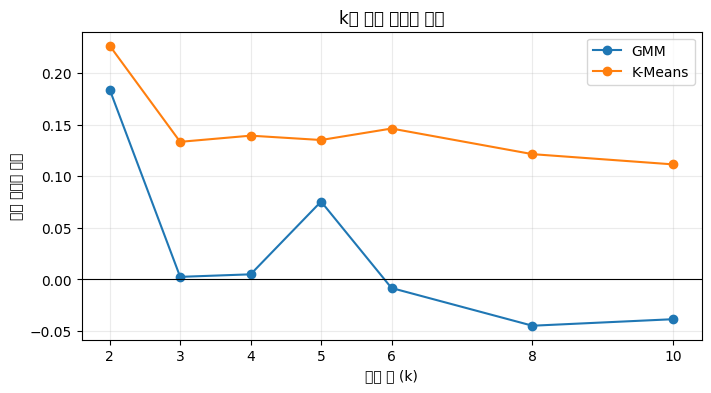

1에 가까울수록 잘 분리되고, 0은 겹침, 음수는 다른 군집에 더 가까울 수 있습니다.


In [99]:
# 실루엣 분석: 평균 점수와 군집별 분포를 함께 확인합니다.
# DBSCAN/Mean Shift에서 노이즈(-1)는 실루엣 계산에서 제외합니다.
from sklearn.metrics import silhouette_samples

silhouette_values = {}
silhouette_scores = {}
for method, labels in visual_labels.items():
    keep = labels != -1
    current = labels[keep]
    ids = np.unique(current)
    if 2 <= len(ids) < len(current):
        values = silhouette_samples(X_viz[keep], current)
        silhouette_values[method] = (values, current)
        silhouette_scores[method] = float(values.mean())

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
axes = axes.ravel()
score_ax = axes[0]
if silhouette_scores:
    score_ax.barh(list(silhouette_scores), list(silhouette_scores.values()), color='#4c78a8')
    score_ax.axvline(0, color='black', linewidth=0.8)
    score_ax.set_xlim(-1, 1)
    score_ax.set_xlabel('평균 실루엣 (-1 ~ 1)')
    score_ax.set_title('알고리즘별 평균 점수')

for ax, (method, labels) in zip(axes[1:], visual_labels.items()):
    if method not in silhouette_values:
        ax.text(0.5, 0.5, '실루엣 계산 불가 (유효 군집 2개 미만)', ha='center', va='center')
        ax.set_title(method)
        ax.set_xlim(-1, 1)
        ax.set_yticks([])
        continue
    values, current = silhouette_values[method]
    y_lower = 10
    for cid in sorted(np.unique(current)):
        part = np.sort(values[current == cid])
        y_upper = y_lower + len(part)
        color = colors(int(cid) % 10)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, part, color=color, alpha=0.75)
        ax.text(-0.08, y_lower + len(part) / 2, str(cid), va='center', fontsize=8)
        y_lower = y_upper + 8
    avg = silhouette_scores[method]
    ax.axvline(avg, color='red', linestyle='--', label=f'평균 {avg:.3f}')
    ax.set_xlim(-1, 1)
    ax.set_xlabel('실루엣 계수')
    ax.set_title(method)
    ax.legend(fontsize=8)
fig.suptitle('실루엣 분석: 군집별 분포', fontsize=15)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for method, group in cluster_comparison[cluster_comparison['method'].isin(['K-Means', 'GMM'])].groupby('method'):
    group = group.sort_values('k')
    ax.plot(group['k'], group['silhouette'], marker='o', label=method)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(sorted(cluster_comparison['k'].unique()))
ax.set_xlabel('군집 수 (k)')
ax.set_ylabel('평균 실루엣 점수')
ax.set_title('k에 따른 실루엣 점수')
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print('1에 가까울수록 잘 분리되고, 0은 겹침, 음수는 다른 군집에 더 가까울 수 있습니다.')

In [132]:
# 실제 추천 검증: K-Means k=6으로 전체 곡을 나눈 뒤, 같은 군집 안에서 KNN 추천을 확인합니다.
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

recommendation_k = 6
X_values = X.to_numpy(dtype=np.float32)
track_info = track_info.reset_index(drop=True).copy()

with threadpool_limits(limits=4):
    recommendation_kmeans = KMeans(
        n_clusters=recommendation_k, n_init=5, random_state=42
    )
    recommendation_labels = recommendation_kmeans.fit_predict(X_values)

recommendation_tracks = track_info.copy()
recommendation_tracks['cluster'] = recommendation_labels
cluster_positions = {}
cluster_knn_models = {}

for cluster_id in np.unique(recommendation_labels):
    positions = np.flatnonzero(recommendation_labels == cluster_id)
    cluster_positions[int(cluster_id)] = positions
    neighbor_model = NearestNeighbors(metric='cosine', algorithm='brute', n_jobs=4)
    neighbor_model.fit(X_values[positions])
    cluster_knn_models[int(cluster_id)] = neighbor_model

def recommend_from_cluster(track_id, n=5):
    matches = np.flatnonzero(track_info['track_id'].astype(str).to_numpy() == str(track_id))
    if len(matches) == 0:
        raise ValueError('해당 track_id를 찾을 수 없습니다.')

    seed_position = int(matches[0])
    cluster_id = int(recommendation_labels[seed_position])
    positions = cluster_positions[cluster_id]
    search_n = min(len(positions), max(n + 1, n * 5))
    distances, local_indices = cluster_knn_models[cluster_id].kneighbors(
        X_values[seed_position:seed_position + 1], n_neighbors=search_n
    )

    seed = track_info.iloc[seed_position]
    seed_key = (str(seed['track_name']).casefold(), str(seed['artists']).casefold())
    seen = set()
    rows = []
    for distance, local_position in zip(distances[0], local_indices[0]):
        candidate_position = int(positions[local_position])
        candidate = track_info.iloc[candidate_position]
        candidate_key = (str(candidate['track_name']).casefold(), str(candidate['artists']).casefold())
        if candidate_position == seed_position or candidate_key == seed_key or candidate_key in seen:
            continue
        seen.add(candidate_key)
        rows.append({
            'track_name': candidate['track_name'],
            'artists': candidate['artists'],
            'album_name': candidate['album_name'],
            'popularity': candidate['popularity'],
            'cosine_similarity': round(float(1 - distance), 4),
        })
        if len(rows) == n:
            break
    return pd.DataFrame(rows)

# 군집마다 인기곡 하나를 골라 추천 결과를 눈으로 비교합니다.
seed_examples = (
    recommendation_tracks.sort_values('popularity', ascending=False, na_position='last')
    .drop_duplicates('cluster')
    .head(recommendation_k)
)

for _, seed in seed_examples.iterrows():
    print(f"군집 {int(seed['cluster'])} | 기준 곡: {seed['track_name']} — {seed['artists']}")
    display(recommend_from_cluster(seed['track_id'], n=5))

군집 0 | 기준 곡: Unholy (feat. Kim Petras) — Sam Smith;Kim Petras


,track_name,artists,album_name,popularity,cosine_similarity
0,Baby Shark (Trap Remix),Pj Panda,"The New Nursery Rhymes, Vol. 1",37,0.9174
1,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,Pj Panda's New Nursery Rhymes Collection,12,0.9174
2,I'd Do Anything to Make You Smile,Jack Harlow,Hip Hop Slow Jamz,0,0.9146
3,I Wouldn't Know Any Better Than You,Gentle Bones,I Wouldn't Know Any Better Than You,62,0.9014
4,Poseidon,gavn!,Poseidon,54,0.8986


군집 2 | 기준 곡: I'm Good (Blue) — David Guetta;Bebe Rexha


,track_name,artists,album_name,popularity,cosine_similarity
0,In My Mind - Axwell Radio Edit,Ivan Gough;Feenixpawl;Georgi Kay;Axwell,In My Mind,63,0.9692
1,Today,Scooter;VASSY,Today,19,0.9680
2,Friday I'm In Love,The Cure,90's Music Grandi Successi,1,0.9608
3,Not In Love - Radio Version,Crystal Castles;Robert Smith,(II),61,0.9388
4,Warriors,Paris Blohm;Nevlin;Romysa,Warriors,51,0.9368


군집 5 | 기준 곡: Ojitos Lindos — Bad Bunny;Bomba Estéreo


...

,track_name,artists,album_name,popularity,cosine_similarity
0,Ajnabi,Zebunissa Bangash,Madras Cafe,35,0.9627
1,Pretty Paper,The Lumineers,Chill Christmas Dinner,0,0.9617
2,Ennavale adi ennavale,Kavya Ajit,Ennavale adi ennavale,18,0.9613
3,Stuck with U - Acoustic,Jonah Baker,Stuck with U (Acoustic),51,0.9516
4,It's Been Heaven Knowing You,Sarah Klang,It's Been Heaven Knowing You,39,0.9506


군집 1 | 기준 곡: everything i wanted — Billie Eilish


,track_name,artists,album_name,popularity,cosine_similarity
0,Pamplemousse,Flavien Berger,Contre-Temps,44,0.9427
1,Nightbook,Ludovico Einaudi,Nightbook (Exclusive),49,0.9380
2,Olomana,Andreas Borkental,Kohala,44,0.9378
3,Shigatsu Wa Kimi No Uso - Hikaru Nara [Soft Ve...,Kenzie Smith Piano,Anime Music Collection Piano Solo Vol.2,42,0.9348
4,Sing for Me,Kochetkovv,Sing for Me,58,0.9347


군집 3 | 기준 곡: Flowers — Lauren Spencer Smith


,track_name,artists,album_name,popularity,cosine_similarity
0,Falador,MC Cebezinho,Falador,42,0.9489
1,Reminiscing,Vluestar,I’ll Keep You Safe,55,0.9468
2,Oh Well (feat. Jace of Two-9),Lil Dicky;Jace,Professional Rapper,52,0.9423
3,The G-Spot 4,Erikka Innes,Sex With Nerds,22,0.9420
4,Poison in My Pocket,Bryce Pinkham;Jefferson Mays;Catherine Walker,A Gentleman's Guide to Love and Murder (Origin...,28,0.9383


In [133]:
# 같은 기준곡으로 전체 KNN과 같은 군집 안 KNN을 비교합니다.
comparison_rows = []
for _, seed in seed_examples.iterrows():
    seed_id = seed['track_id']
    seed_name = seed['track_name']
    seed_artist = seed['artists']

    result_sets = [
        ('전체 곡에서 KNN', recommend_knn(seed_id, n=5)),
        ('같은 군집 안에서 KNN', recommend_from_cluster(seed_id, n=5)),
    ]
    for method, recommendations in result_sets:
        for rank, (_, rec) in enumerate(recommendations.iterrows(), start=1):
            comparison_rows.append({
                '기준 곡': seed_name,
                '기준 아티스트': seed_artist,
                '추천 방식': method,
                '순위': rank,
                '추천 곡': rec['track_name'],
                '아티스트': rec['artists'],
                '코사인 유사도': rec['cosine_similarity'],
            })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round({'코사인 유사도': 3}))

print('참고: 코사인 유사도는 오디오 특성의 수치상 가까움을 뜻하며, 사람이 느끼는 추천 적합도와 같지는 않습니다.')

,기준 곡,기준 아티스트,추천 방식,순위,추천 곡,아티스트,코사인 유사도
0,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,전체 곡에서 KNN,1,Shower,Becky G,0.948
1,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,전체 곡에서 KNN,2,Super Gremlin Freestyle,BadKidMacei,0.940
2,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,전체 곡에서 KNN,3,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,0.917
3,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,전체 곡에서 KNN,4,Baby Shark (Trap Remix),Pj Panda,0.917
4,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,전체 곡에서 KNN,5,I'd Do Anything to Make You Smile,Jack Harlow,0.915
5,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,같은 군집 안에서 KNN,1,Baby Shark (Trap Remix),Pj Panda,0.917
6,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,같은 군집 안에서 KNN,2,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,0.917
7,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,같은 군집 안에서 KNN,3,I'd Do Anything to Make You Smile,Jack Harlow,0.915
8,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,같은 군집 안에서 KNN,4,I Wouldn't Know Any Better Than You,Gentle Bones,0.901
9,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,같은 군집 안에서 KNN,5,Poseidon,gavn!,0.899


참고: 코사인 유사도는 오디오 특성의 수치상 가까움을 뜻하며, 사람이 느끼는 추천 적합도와 같지는 않습니다.


In [134]:
# 군집 제한은 빼고, 어떤 오디오 특성 구성이 추천을 더 납득 가능하게 만드는지 비교합니다.
from sklearn.neighbors import NearestNeighbors

rhythm_mood_cols = ['danceability', 'energy', 'loudness', 'valence', 'tempo']
feature_matrices = {
    '현재 전체 특성(오디오+key/mode/time_signature)': X_values,
    '연속형 오디오 특성(곡 길이 포함)': X_continuous.to_numpy(dtype=np.float32),
    '연속형 오디오 특성(곡 길이 제외)': X_continuous.drop(columns=['duration_ms']).to_numpy(dtype=np.float32),
    '리듬·에너지·분위기 중심': X_continuous[rhythm_mood_cols].to_numpy(dtype=np.float32),
}

feature_knn_models = {}
for feature_name, matrix in feature_matrices.items():
    model = NearestNeighbors(metric='cosine', algorithm='brute', n_jobs=4)
    model.fit(matrix)
    feature_knn_models[feature_name] = model

test_seed_names = ['Unholy (feat. Kim Petras)', "I'm Good (Blue)", 'Glimpse of Us']
feature_rows = []
for seed_name in test_seed_names:
    seed_positions = np.flatnonzero(track_info['track_name'].to_numpy() == seed_name)
    if len(seed_positions) == 0:
        print(f'기준 곡을 찾지 못해 건너뜀: {seed_name}')
        continue
    seed_position = int(seed_positions[0])
    seed = track_info.iloc[seed_position]
    seed_key = (str(seed['track_name']).casefold(), str(seed['artists']).casefold())

    for feature_name, matrix in feature_matrices.items():
        search_n = min(100, len(matrix))
        distances, indices = feature_knn_models[feature_name].kneighbors(
            matrix[seed_position:seed_position + 1], n_neighbors=search_n
        )
        seen = set()
        rank = 0
        for distance, candidate_position in zip(distances[0], indices[0]):
            candidate_position = int(candidate_position)
            candidate = track_info.iloc[candidate_position]
            candidate_key = (str(candidate['track_name']).casefold(), str(candidate['artists']).casefold())
            if candidate_position == seed_position or candidate_key == seed_key or candidate_key in seen:
                continue
            seen.add(candidate_key)
            rank += 1
            feature_rows.append({
                '기준 곡': seed_name,
                '특성 구성': feature_name,
                '순위': rank,
                '추천 곡': candidate['track_name'],
                '아티스트': candidate['artists'],
                '코사인 유사도': round(float(1 - distance), 3),
            })
            if rank == 5:
                break

feature_comparison = pd.DataFrame(feature_rows)
display(feature_comparison)
print('유사도 숫자만으로 최종 특성을 고르지 말고, 기준 곡별 추천 목록이 실제로 비슷하게 들리는지 함께 확인하세요.')

,기준 곡,특성 구성,순위,추천 곡,아티스트,코사인 유사도
0,Unholy (feat. Kim Petras),현재 전체 특성(오디오+key/mode/time_signature),1,Shower,Becky G,0.948
1,Unholy (feat. Kim Petras),현재 전체 특성(오디오+key/mode/time_signature),2,Super Gremlin Freestyle,BadKidMacei,0.940
2,Unholy (feat. Kim Petras),현재 전체 특성(오디오+key/mode/time_signature),3,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,0.917
3,Unholy (feat. Kim Petras),현재 전체 특성(오디오+key/mode/time_signature),4,Baby Shark (Trap Remix),Pj Panda,0.917
4,Unholy (feat. Kim Petras),현재 전체 특성(오디오+key/mode/time_signature),5,I'd Do Anything to Make You Smile,Jack Harlow,0.915
5,Unholy (feat. Kim Petras),연속형 오디오 특성(곡 길이 포함),1,I Know You (feat. Bastille) - Vigiland Remix,Craig David;Bastille;Vigiland,0.968
6,Unholy (feat. Kim Petras),연속형 오디오 특성(곡 길이 포함),2,Walk,Kodak Black,0.952
7,Unholy (feat. Kim Petras),연속형 오디오 특성(곡 길이 포함),3,Duydum Ki,Taladro;R-Ash,0.932
8,Unholy (feat. Kim Petras),연속형 오디오 특성(곡 길이 포함),4,Metas e Versos (feat. Brunno Ramos),DJ Roger Vale;Zack Vox;Gabriel Bulian;Brunno R...,0.923
9,Unholy (feat. Kim Petras),연속형 오디오 특성(곡 길이 포함),5,2AM,Ryan Oakes,0.915


유사도 숫자만으로 최종 특성을 고르지 말고, 기준 곡별 추천 목록이 실제로 비슷하게 들리는지 함께 확인하세요.


In [ ]:
# 추천 품질은 실제로 들어보고 직접 평가합니다: 0=안 비슷함, 1=조금 비슷함, 2=비슷함
review_candidates = (
    feature_comparison.loc[feature_comparison['순위'] <= 3,
                          ['기준 곡', '특성 구성', '추천 곡', '아티스트', '코사인 유사도']]
    .drop_duplicates(['기준 곡', '추천 곡', '아티스트'])
    .sort_values(['기준 곡', '특성 구성', '코사인 유사도'], ascending=[True, True, False])
    .reset_index(drop=True)
)

# 실제로 들어본 뒤 아래에 점수를 입력하고 이 셀을 다시 실행하세요.
# 키 형식: (기준 곡, 추천 곡, 아티스트): 점수
manual_ratings = {
    # ('Unholy (feat. Kim Petras)', 'Shower', 'Becky G'): 0,
}

def rating_for(row):
    key = (str(row['기준 곡']), str(row['추천 곡']), str(row['아티스트']))
    return manual_ratings.get(key, np.nan)

review_candidates['직접 평가(0~2)'] = review_candidates.apply(rating_for, axis=1)
display(review_candidates)

rated_comparison = feature_comparison.loc[feature_comparison['순위'] <= 3].copy()
rated_comparison['직접 평가(0~2)'] = rated_comparison.apply(rating_for, axis=1)
rated_comparison = rated_comparison.dropna(subset=['직접 평가(0~2)'])
if rated_comparison.empty:
    print('표의 곡을 들어본 뒤 manual_ratings에 0, 1, 2 점수를 입력하면 구성별 평균 점수가 나옵니다.')
else:
    rating_summary = (
        rated_comparison.groupby(['기준 곡', '특성 구성'])['직접 평가(0~2)']
        .agg(['mean', 'count'])
        .rename(columns={'mean': '평균 직접 평가', 'count': '평가한 추천 수'})
        .round(2)
    )
    display(rating_summary)

,기준 곡,특성 구성,추천 곡,아티스트,코사인 유사도,직접 평가(0~2)
0,Glimpse of Us,리듬·에너지·분위기 중심,Roses Are Red (Violets Are Blue),Jon Caryl,0.997,NaN
1,Glimpse of Us,리듬·에너지·분위기 중심,クレイジー・サマー,KIRINJI,0.997,NaN
2,Glimpse of Us,연속형 오디오 특성(곡 길이 제외),Mi Último Fracaso,Juanafé;La Flor del Recuerdo,0.988,NaN
3,Glimpse of Us,연속형 오디오 특성(곡 길이 포함),One Day Less,Anson Seabra,0.994,NaN
4,Glimpse of Us,연속형 오디오 특성(곡 길이 포함),World's Best Friend,Original Cast of Amélie,0.988,NaN
5,Glimpse of Us,연속형 오디오 특성(곡 길이 포함),Make It Easy On Yourself,Gail Blanco,0.987,NaN
6,Glimpse of Us,현재 전체 특성(오디오+key/mode/time_signature),Ajnabi,Zebunissa Bangash,0.963,NaN
7,Glimpse of Us,현재 전체 특성(오디오+key/mode/time_signature),Pretty Paper,The Lumineers,0.962,NaN
8,Glimpse of Us,현재 전체 특성(오디오+key/mode/time_signature),Ennavale adi ennavale,Kavya Ajit,0.961,NaN
9,I'm Good (Blue),리듬·에너지·분위기 중심,Attention Please,Caroline's Spine,0.999,NaN


표의 곡을 들어본 뒤 manual_ratings에 0, 1, 2 점수를 입력하면 구성별 평균 점수가 나옵니다.


In [136]:
# 웹페이지 연결용 기본 흐름: 인기 Top 100 목록 + 선택 곡의 추천/플레이리스트
# 임시 기준은 전체 특성 KNN이며, 특성 평가와 가중치 조정은 나중에 반영합니다.
top100_tracks = (
    track_info.sort_values(
        ['popularity', 'track_name'], ascending=[False, True]
    )
    .head(100)
    .reset_index(drop=True)
)
top100_tracks.insert(0, '순위', np.arange(1, len(top100_tracks) + 1))

def build_track_page(track_id, recommendation_count=5, playlist_size=20):
    """선택한 곡의 정보, 추천곡, 선택곡으로 시작하는 플레이리스트를 반환합니다."""
    if recommendation_count < 0 or playlist_size < 1:
        raise ValueError('추천 개수는 0 이상, 플레이리스트 크기는 1 이상이어야 합니다.')

    matches = np.flatnonzero(
        track_info['track_id'].astype(str).to_numpy() == str(track_id)
    )
    if len(matches) == 0:
        raise ValueError('선택한 track_id를 데이터에서 찾을 수 없습니다.')

    seed = track_info.iloc[int(matches[0])]
    recommendation_n = min(
        max(recommendation_count, playlist_size - 1), len(track_info) - 1
    )
    ranked = recommend_knn(seed['track_id'], n=recommendation_n)

    recommendations = ranked.head(recommendation_count).copy().reset_index(drop=True)
    recommendations.insert(0, '순위', np.arange(1, len(recommendations) + 1))

    seed_row = seed.to_dict()
    seed_row['cosine_similarity'] = 1.0
    seed_row['구분'] = '선택한 곡'
    playlist_recommendations = ranked.head(playlist_size - 1).copy()
    playlist_recommendations['구분'] = '추천곡'
    playlist = pd.concat(
        [pd.DataFrame([seed_row]), playlist_recommendations],
        ignore_index=True
    )
    playlist.insert(0, '순서', np.arange(1, len(playlist) + 1))

    return {
        'selected_track': seed,
        'recommendations': recommendations,
        'playlist': playlist
    }

# 동작 예시: Top 100의 첫 곡을 선택한 것으로 보고 결과 확인
display(top100_tracks.head(10))
demo_track = top100_tracks.iloc[0]
demo_page = build_track_page(demo_track['track_id'])
print('선택한 곡:', demo_page['selected_track']['track_name'], '—', demo_page['selected_track']['artists'])
print('추천곡 목록')
display(demo_page['recommendations'])
print('선택한 곡으로 시작하는 플레이리스트')
display(demo_page['playlist'])

,순위,track_id,track_name,artists,album_name,popularity
0,1,3nqQXoyQOWXiESFLlDF1hG,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,Unholy (feat. Kim Petras),100
1,2,2tTmW7RDtMQtBk7m2rYeSw,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,"Quevedo: Bzrp Music Sessions, Vol. 52",99
2,3,4uUG5RXrOk84mYEfFvj3cK,I'm Good (Blue),David Guetta;Bebe Rexha,I'm Good (Blue),98
3,4,5ww2BF9slyYgNOk37BlC4u,La Bachata,Manuel Turizo,La Bachata,98
4,5,6Sq7ltF9Qa7SNFBsV5Cogx,Me Porto Bonito,Bad Bunny;Chencho Corleone,Un Verano Sin Ti,97
5,6,1IHWl5LamUGEuP4ozKQSXZ,Tití Me Preguntó,Bad Bunny,Un Verano Sin Ti,97
6,7,5Eax0qFko2dh7Rl2lYs3bx,Efecto,Bad Bunny,Un Verano Sin Ti,96
7,8,4h9wh7iOZ0GGn8QVp4RAOB,I Ain't Worried,OneRepublic,I Ain’t Worried (Music From The Motion Picture...,96
8,9,5IgjP7X4th6nMNDh4akUHb,Under The Influence,Chris Brown,Indigo (Extended),96
9,10,4LRPiXqCikLlN15c3yImP7,As It Was,Harry Styles,As It Was,95


선택한 곡: Unholy (feat. Kim Petras) — Sam Smith;Kim Petras
추천곡 목록


,순위,track_id,track_name,artists,album_name,popularity,cosine_similarity
0,1,3DmW6y7wTEYHJZlLo1r6XJ,Shower,Becky G,Shower,78,0.947663
1,2,100fdP6bcT8byvdEdAAcTJ,Super Gremlin Freestyle,BadKidMacei,Super Gremlin Freestyle,23,0.940423
2,3,6VTHp0HzlexVgCZcuV2bkT,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,Pj Panda's New Nursery Rhymes Collection,12,0.917389
3,4,2mIfukfnSxDiMbh9xOxeZN,Baby Shark (Trap Remix),Pj Panda,"The New Nursery Rhymes, Vol. 1",37,0.917389
4,5,3mfsGLEmKF6sWTqFQzZ4aF,I'd Do Anything to Make You Smile,Jack Harlow,Hip Hop Slow Jamz,0,0.914592


선택한 곡으로 시작하는 플레이리스트


,순서,track_id,track_name,artists,album_name,popularity,cosine_similarity,구분
0,1,3nqQXoyQOWXiESFLlDF1hG,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,Unholy (feat. Kim Petras),100,1.000000,선택한 곡
1,2,3DmW6y7wTEYHJZlLo1r6XJ,Shower,Becky G,Shower,78,0.947663,추천곡
2,3,100fdP6bcT8byvdEdAAcTJ,Super Gremlin Freestyle,BadKidMacei,Super Gremlin Freestyle,23,0.940423,추천곡
3,4,6VTHp0HzlexVgCZcuV2bkT,Baby Shark (Trap Remix),Pj Panda;ML3V LLC,Pj Panda's New Nursery Rhymes Collection,12,0.917389,추천곡
4,5,2mIfukfnSxDiMbh9xOxeZN,Baby Shark (Trap Remix),Pj Panda,"The New Nursery Rhymes, Vol. 1",37,0.917389,추천곡
5,6,3mfsGLEmKF6sWTqFQzZ4aF,I'd Do Anything to Make You Smile,Jack Harlow,Hip Hop Slow Jamz,0,0.914592,추천곡
6,7,4DfRseYfBS7cjHKidKxmS7,İyi Değilim,Sinan Akçıl;İrem Derici,Piyanist 2,37,0.904958,추천곡
7,8,3K8tRD2Prik7FXbD8lZ6DC,I Wouldn't Know Any Better Than You,Gentle Bones,I Wouldn't Know Any Better Than You,62,0.901366,추천곡
8,9,173oDK5CIOLGUvLdudCnUa,Poseidon,gavn!,Poseidon,54,0.898602,추천곡
9,10,2CwE41FCKT4rr8WmBsOrFr,Thank You,JUNNY,Thank You,59,0.896677,추천곡
